<a href="https://colab.research.google.com/github/jamoffl3/24ADI006-DEEP-LEARNING/blob/main/24BAD038_DL_EX_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment No. 8
## Generation of Synthetic Images Using a Generative Adversarial Network (GAN)

**Name:** JAMUNA VP
**Register Number:** 24BAD038



## Part A: Dataset Preparation

Register Number: 24BAD038
TensorFlow version: 2.21.0
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training shape: (60000, 28, 28)
Testing shape: (10000, 28, 28)
Original pixel range: 0 to 255
Prepared training shape: (60000, 28, 28, 1)
Prepared testing shape: (10000, 28, 28, 1)
Normalized range: -1.0 to 1.0


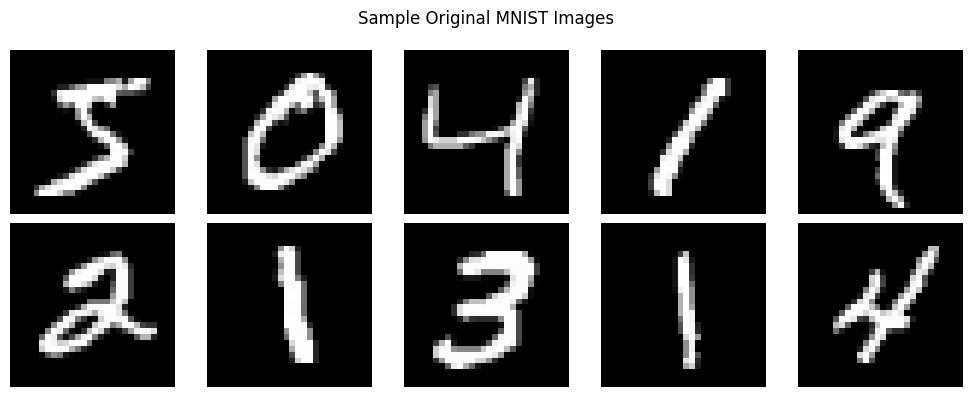

Batch size: 128


In [ ]:
REGISTER_NUMBER = "24BAD038"
print("Register Number:", REGISTER_NUMBER)
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import mnist
print("TensorFlow version:", tf.__version__)
(x_train, _), (x_test, _) = mnist.load_data()
print("Training shape:", x_train.shape)
print("Testing shape:", x_test.shape)
print("Original pixel range:", x_train.min(), "to", x_train.max())
# Normalize pixels from [0, 255] to [-1, 1]
x_train = (x_train.astype("float32") - 127.5) / 127.5
x_test = (x_test.astype("float32") - 127.5) / 127.5
# Add channel dimension
x_train = np.expand_dims(x_train, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)
print("Prepared training shape:", x_train.shape)
print("Prepared testing shape:", x_test.shape)
print("Normalized range:", x_train.min(), "to", x_train.max())
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i].squeeze(), cmap="gray", vmin=-1, vmax=1)
    plt.axis("off")
plt.suptitle("Sample Original MNIST Images")
plt.tight_layout()
plt.show()
BATCH_SIZE = 128
train_dataset = (tf.data.Dataset.from_tensor_slices(x_train)
                 .shuffle(60000).batch(BATCH_SIZE, drop_remainder=True))
print("Batch size:", BATCH_SIZE)

## Part B: Implementing the Generator and Discriminator

In [ ]:
from tensorflow.keras import layers

NOISE_DIM = 100

# Generator converts a random noise vector into a 28 x 28 image
def build_generator():
    return tf.keras.Sequential([
        layers.Input(shape=(NOISE_DIM,)),
        layers.Dense(256),
        layers.LeakyReLU(negative_slope=0.2),
        layers.Dense(512),
        layers.LeakyReLU(negative_slope=0.2),
        layers.Dense(784, activation="tanh"),
        layers.Reshape((28, 28, 1))
    ], name="Generator")

# Discriminator classifies an image as real or fake
def build_discriminator():
    return tf.keras.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Flatten(),
        layers.Dense(512),
        layers.LeakyReLU(negative_slope=0.2),
        layers.Dense(256),
        layers.LeakyReLU(negative_slope=0.2),
        layers.Dense(1)
    ], name="Discriminator")

generator = build_generator()
discriminator = build_discriminator()

print("GENERATOR SUMMARY")
generator.summary()
print("\nDISCRIMINATOR SUMMARY")
discriminator.summary()

GENERATOR SUMMARY


Model: "Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │        25,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 512)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 784)            │       402,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 28, 28, 1)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 559,632 (2.13 MB)

 Trainable params: 559,632 (2.13 MB)

 Non-trainable params: 0 (0.00 B)

... (2 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 533,505 (2.04 MB)

 Trainable params: 533,505 (2.04 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Define Binary Cross-Entropy loss and Adam optimizers
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)
generator_optimizer = tf.keras.optimizers.Adam(0.0002, beta_1=0.5)
discriminator_optimizer = tf.keras.optimizers.Adam(0.0002, beta_1=0.5)

def generator_loss(fake_output):
    return cross_entropy(tf.ones_like(fake_output), fake_output)

def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(tf.ones_like(real_output), real_output)
    fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)
    return real_loss + fake_loss

print("Optimizer: Adam")
print("Loss function: Binary Cross-Entropy")
print("Generator and Discriminator loss functions are ready.")

Optimizer: Adam
Loss function: Binary Cross-Entropy
Generator and Discriminator loss functions are ready.


## Part C: GAN Training and Performance Monitoring

Epoch 1/10 | Generator Loss: 0.9927 | Discriminator Loss: 0.9019


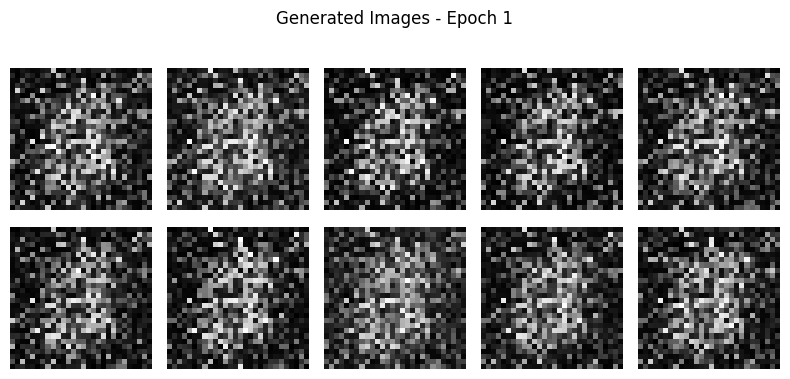

Epoch 2/10 | Generator Loss: 1.5733 | Discriminator Loss: 0.6005


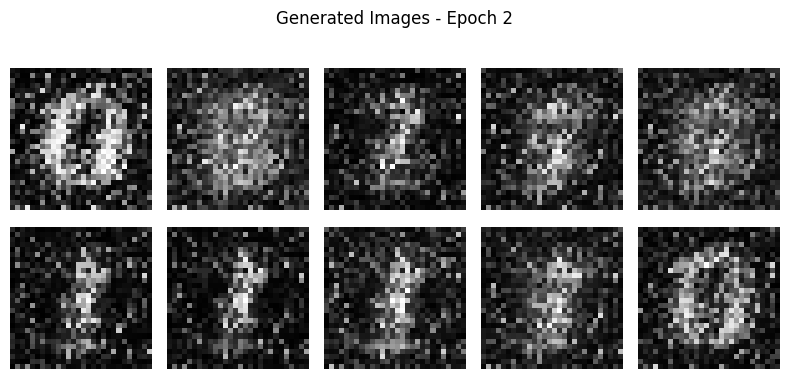

Epoch 3/10 | Generator Loss: 1.5159 | Discriminator Loss: 0.6814


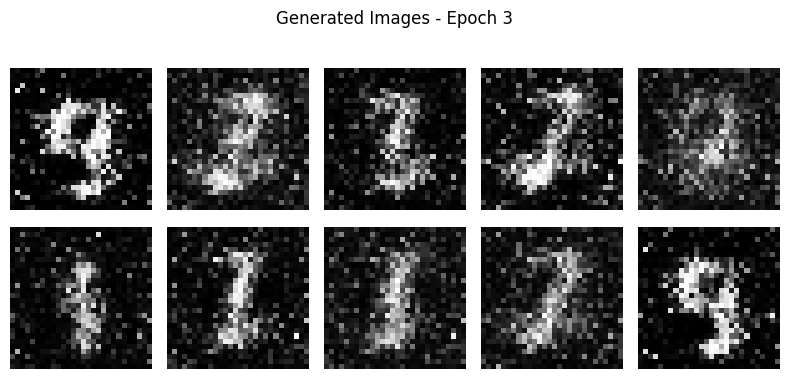

Epoch 4/10 | Generator Loss: 1.5987 | Discriminator Loss: 0.7070


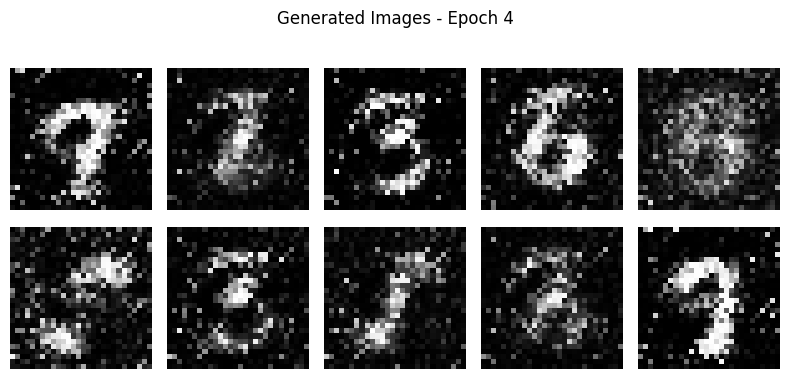

Epoch 5/10 | Generator Loss: 1.6925 | Discriminator Loss: 0.6782


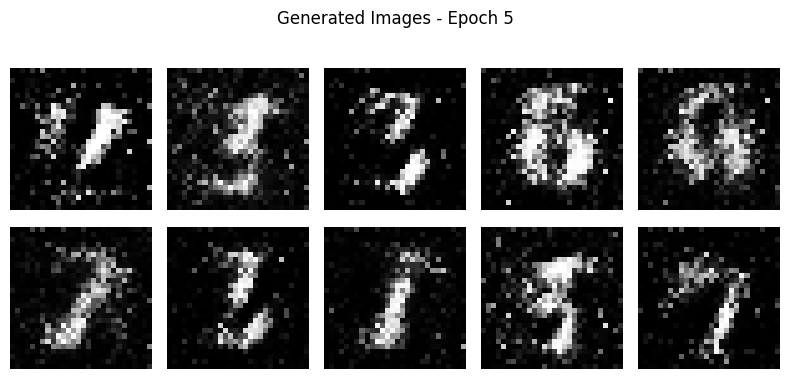

Epoch 6/10 | Generator Loss: 1.7044 | Discriminator Loss: 0.6788


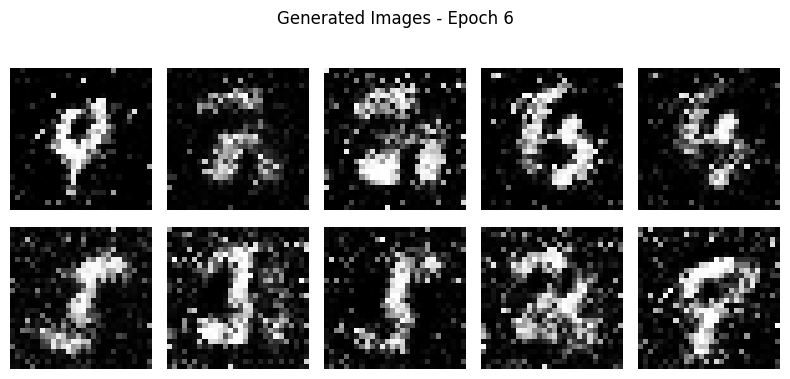

Epoch 7/10 | Generator Loss: 1.6805 | Discriminator Loss: 0.7155


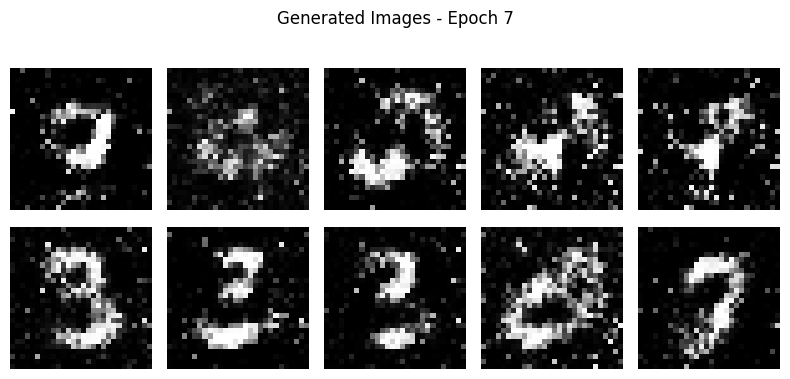

Epoch 8/10 | Generator Loss: 1.7411 | Discriminator Loss: 0.6696


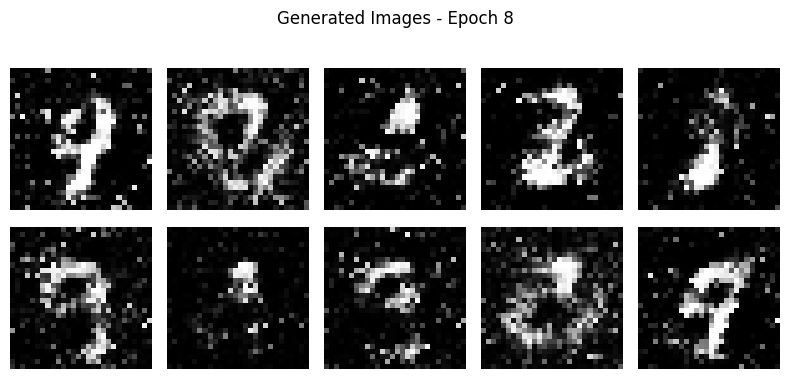

Epoch 9/10 | Generator Loss: 1.6522 | Discriminator Loss: 0.7577


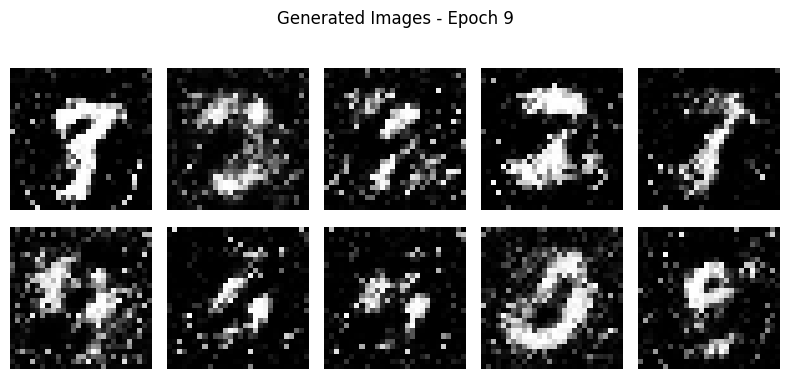

Epoch 10/10 | Generator Loss: 1.8017 | Discriminator Loss: 0.6593


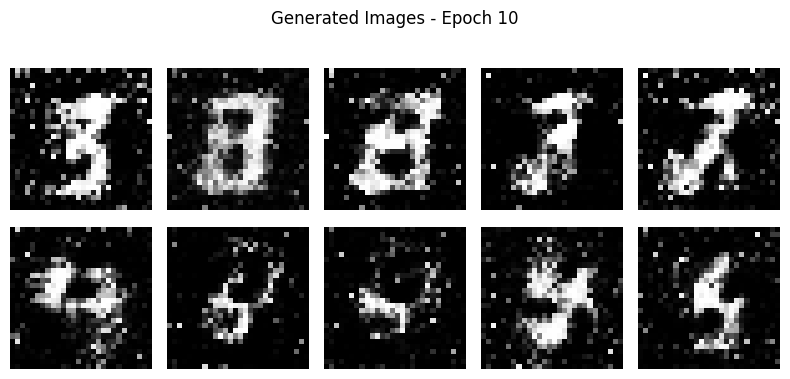

In [ ]:
@tf.function
def train_step(real_images):
    noise = tf.random.normal([BATCH_SIZE, NOISE_DIM])

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        generated_images = generator(noise, training=True)
        real_output = discriminator(real_images, training=True)
        fake_output = discriminator(generated_images, training=True)

        gen_loss = generator_loss(fake_output)
        disc_loss = discriminator_loss(real_output, fake_output)

    gen_gradients = gen_tape.gradient(gen_loss, generator.trainable_variables)
    disc_gradients = disc_tape.gradient(disc_loss, discriminator.trainable_variables)

    generator_optimizer.apply_gradients(zip(gen_gradients, generator.trainable_variables))
    discriminator_optimizer.apply_gradients(zip(disc_gradients, discriminator.trainable_variables))
    return gen_loss, disc_loss

def display_generated_images(model, epoch, seed):
    images = model(seed, training=False)
    images = (images + 1) / 2.0
    plt.figure(figsize=(8, 4))
    for i in range(10):
        plt.subplot(2, 5, i + 1)
        plt.imshow(images[i, :, :, 0], cmap="gray")
        plt.axis("off")
    plt.suptitle(f"Generated Images - Epoch {epoch}")
    plt.tight_layout()
    plt.show()

fixed_seed = tf.random.normal([10, NOISE_DIM])
EPOCHS = 10
generator_losses, discriminator_losses = [], []

for epoch in range(1, EPOCHS + 1):
    g_metric = tf.keras.metrics.Mean()
    d_metric = tf.keras.metrics.Mean()

    for real_batch in train_dataset:
        g_loss, d_loss = train_step(real_batch)
        g_metric.update_state(g_loss)
        d_metric.update_state(d_loss)

    g_value = float(g_metric.result())
    d_value = float(d_metric.result())
    generator_losses.append(g_value)
    discriminator_losses.append(d_value)

    print(f"Epoch {epoch}/{EPOCHS} | Generator Loss: {g_value:.4f} | Discriminator Loss: {d_value:.4f}")
    display_generated_images(generator, epoch, fixed_seed)

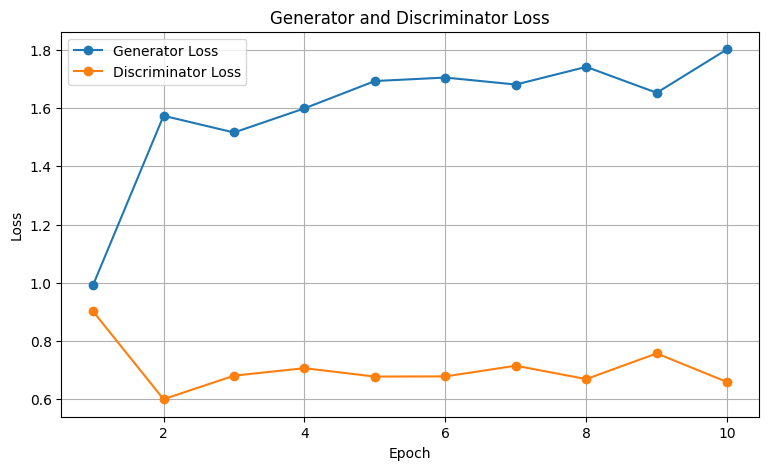

In [ ]:
plt.figure(figsize=(9, 5))
plt.plot(range(1, EPOCHS + 1), generator_losses, marker="o", label="Generator Loss")
plt.plot(range(1, EPOCHS + 1), discriminator_losses, marker="o", label="Discriminator Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Generator and Discriminator Loss")
plt.legend()
plt.grid(True)
plt.show()

## Part D: Synthetic Image Generation, Comparison and Experiment Management

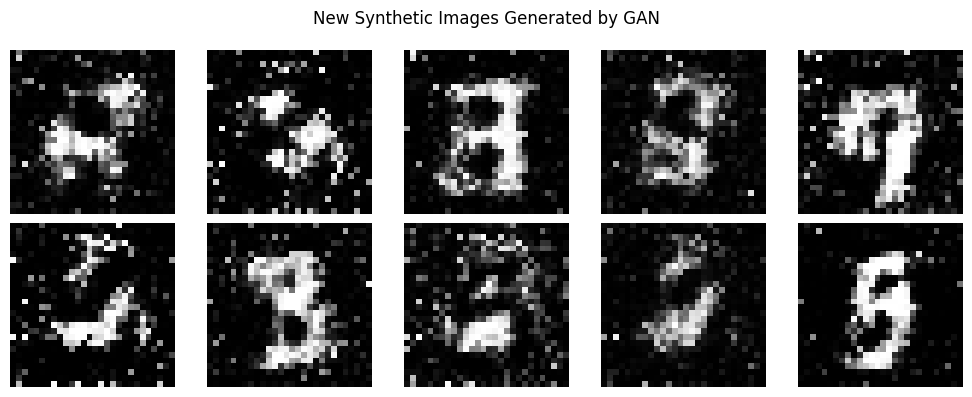

In [ ]:
# Generate new images using fresh random noise
new_noise = tf.random.normal([10, NOISE_DIM])
synthetic_images = generator(new_noise, training=False)
synthetic_images = (synthetic_images + 1) / 2.0

plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(synthetic_images[i, :, :, 0], cmap="gray")
    plt.axis("off")
plt.suptitle("New Synthetic Images Generated by GAN")
plt.tight_layout()
plt.show()

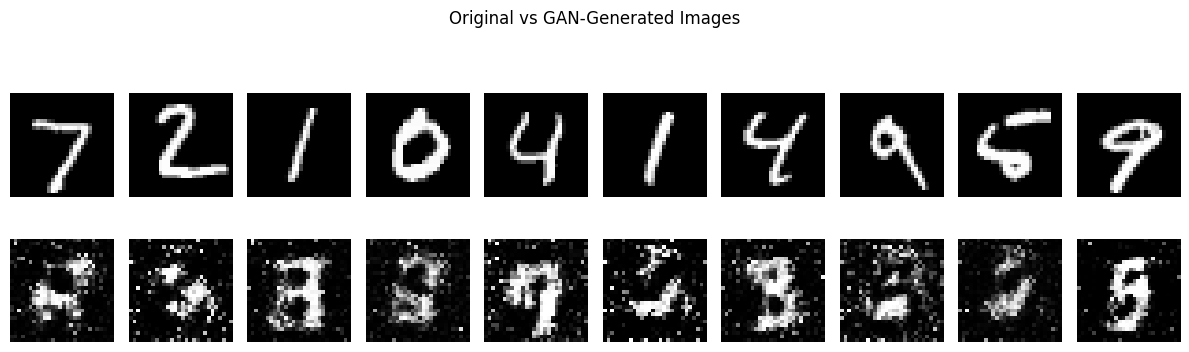

In [ ]:
# Compare original MNIST images with generated synthetic images
real_samples = (x_test[:10] + 1) / 2.0

plt.figure(figsize=(12, 4))
for i in range(10):
    plt.subplot(2, 10, i + 1)
    plt.imshow(real_samples[i].squeeze(), cmap="gray")
    plt.axis("off")
    if i == 0:
        plt.ylabel("Original")

    plt.subplot(2, 10, i + 11)
    plt.imshow(synthetic_images[i, :, :, 0], cmap="gray")
    plt.axis("off")
    if i == 0:
        plt.ylabel("Generated")

plt.suptitle("Original vs GAN-Generated Images")
plt.tight_layout()
plt.show()